# Задача №2. Центральность в графе друзей

Датасет SNAP ego-Facebook. Его собирали так: взяли 10 человек (ego), их друзей и дружбу между этими друзьями. Эти 10 человек играют роль членов группы.

Для них считаем три индекса:

- по близости — насколько человек близок ко всем остальным (короткие пути до всех)
- по посредничеству — сколько кратчайших путей между другими людьми проходит через человека
- по собственному вектору — человек важен, если дружит с важными людьми

In [9]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

## Данные

In [10]:
edges = pd.read_csv("facebook_combined.txt.gz", sep=" ", names=["a", "b"])
G = nx.from_pandas_edgelist(edges, "a", "b")
print(G.number_of_nodes(), "человек,", G.number_of_edges(), "дружб")

4039 человек, 88234 дружб


In [11]:
group = [0, 107, 348, 414, 686, 698, 1684, 1912, 3437, 3980, 2, 5, 10, 1337]

## Центральность

In [12]:
closeness = nx.closeness_centrality(G)
betweenness = nx.betweenness_centrality(G)
eigenvector = nx.eigenvector_centrality_numpy(G)

table = pd.DataFrame({
    "друзей": dict(G.degree()),
    "близость": closeness,
    "посредничество": betweenness,
    "собств. вектор": eigenvector,
})
places = table.rank(ascending=False).astype(int)

Индексы для членов группы и их место среди всех 4039 человек:

In [13]:
result = table.loc[group].join(places.loc[group], rsuffix=" (место)")
result.sort_values("посредничество", ascending=False)

,друзей,близость,посредничество,собств. вектор,друзей (место),близость (место),посредничество (место),собств. вектор (место)
107,1045,0.459699,4.805181e-01,1.672667e-04,1,1,1,757
1684,792,0.393606,3.377974e-01,6.124397e-06,2,5,2,1149
3437,547,0.314413,2.361154e-01,7.646593e-08,4,1050,3,2557
1912,755,0.350947,2.292953e-01,9.540586e-02,3,28,4,1
0,347,0.353343,1.463059e-01,3.313350e-05,5,27,6,801
698,68,0.271189,1.153305e-01,7.864096e-10,826,2245,7,3367
414,159,0.369543,4.763337e-02,1.104537e-05,180,9,13,1008
348,229,0.369916,3.799810e-02,1.331780e-05,14,7,15,968
686,170,0.216910,2.972190e-02,5.901773e-12,141,3781,17,3837
3980,59,0.225448,2.482003e-02,4.697123e-08,983,3777,20,2950


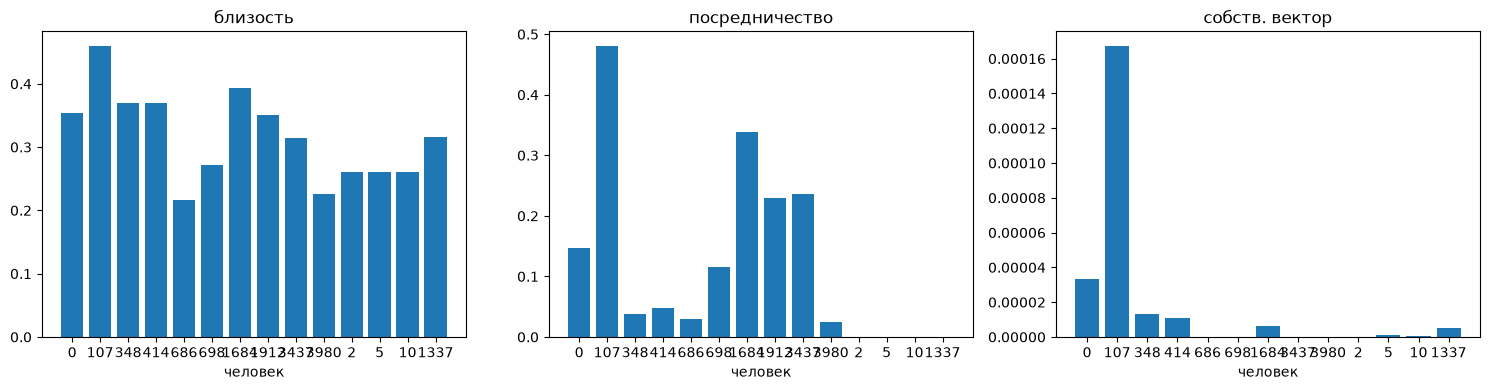

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["близость", "посредничество", "собств. вектор"]):
    people = [u for u in group if not (col == "собств. вектор" and u == 1912)]
    ax.bar([str(u) for u in people], table.loc[people, col])
    ax.set_title(col)
    ax.set_xlabel("человек")
plt.tight_layout()
plt.show()

## Выводы

Выводы допишите после прогона по таблице выше. На что смотреть:

- Лидер по числу друзей совпадает с лидером по посредничеству
- Близость у всех обычно похожая: граф плотный, почти любые двое связаны через 3–4 рукопожатия
- Собственный вектор высокий у тех, чьи друзья сами популярны